# 0. CONFIG

In [24]:
import os
import json
import math
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from pathlib import Path

# Config
RANDOM_SEED = 42
TIME_RESOLUTION_MINUTES = 15
STEPS_PER_DAY = int(24 * 60 / TIME_RESOLUTION_MINUTES) # 96 steps
ACN_SITES = ["caltech", "jpl"]
START_DATE = "2021-01-01"
END_DATE = "2021-12-31"

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True, parents=True)
OUTPUT_PATH = DATA_DIR / "ev_profiles.csv"

# Assumptions: Mix of behaviour types in the network
BEHAVIOUR_MIX = {
    "workplace": 0.5,
    "residential": 0.3,
    "public": 0.15,
    "fast_charging": 0.05
}

np.random.seed(RANDOM_SEED)

# Read ACN_API_KEY from environment variable (dotenv) if possible
try:
    from dotenv import load_dotenv, find_dotenv
    load_dotenv(find_dotenv())
except ImportError:
    print("Note: python-dotenv not installed. If .env file loading is required, run `pip install python-dotenv`.")

ACN_API_KEY = os.environ.get("ACN_API_KEY")
print("Token loaded:", bool(ACN_API_KEY))


if not ACN_API_KEY:
    print("Warning: ACN_API_KEY environment variable not set. API calls might fail if rate limited or unauthorized.")

Token loaded: True


# 1. LOAD DATA

In [26]:
from urllib.parse import urljoin  # Safely build ACN pagination URLs

API_BASE = "https://ev.caltech.edu/api/v1/"


def fetch_acn_data(site, start_date, end_date, token, cache_path):
    if cache_path.exists():
        print(f"Loading {site} from cache...")
        return pd.read_pickle(cache_path)

    print(f"Downloading {site} data from ACN API...")

    url = urljoin(
        API_BASE,
        f"sessions/{site}",
    )  # Build the correct ACN endpoint

    start = pd.to_datetime(start_date).strftime(
        "%a, %d %b %Y 00:00:00 GMT"
    )
    end = pd.to_datetime(end_date).strftime(
        "%a, %d %b %Y 23:59:59 GMT"
    )

    all_sessions = []

    try:
        from acnportal import acndata

        print("Using acnportal package to fetch data")
        client = acndata.DataClient(token)

        sessions = client.get_sessions(
            site,
            cond=f"connectionTime>='{start}' and connectionTime<='{end}'",
        )

        all_sessions = list(sessions)
        df = pd.DataFrame(all_sessions)

    except ImportError:
        print("acnportal not installed, using direct REST API")

        auth = (token, "") if token else None

        current_url = (
            url
            + f"?where=connectionTime>='{start}'"
            + f" and connectionTime<='{end}'"
        )

        while current_url:
            resp = requests.get(
                current_url,
                auth=auth,
                timeout=30,
            )  # Fetch one page with normal HTTPS verification

            if resp.status_code == 401:
                print("Unauthorized. Please check your ACN_API_KEY.")
                break

            if resp.status_code != 200:
                print(f"Error {resp.status_code}: {resp.text}")
                break

            data = resp.json()

            if "_items" in data:
                all_sessions.extend(data["_items"])

            next_link = data.get("_links", {}).get("next")

            if not next_link:
                current_url = None
                continue

            next_href = next_link["href"]

            if next_href.startswith(("http://", "https://")):
                current_url = next_href

            elif next_href.startswith("/api/v1/"):
                current_url = "https://ev.caltech.edu" + next_href

            else:
                current_url = urljoin(
                    API_BASE,
                    next_href.lstrip("/"),
                )

        df = pd.DataFrame(all_sessions)

    if not df.empty:
        df.to_pickle(cache_path)

    return df


dfs = []

for site in ACN_SITES:
    cache_file = (
        DATA_DIR
        / f"acn_{site}_{START_DATE}_{END_DATE}.pkl"
    )

    dfs.append(
        fetch_acn_data(
            site,
            START_DATE,
            END_DATE,
            ACN_API_KEY,
            cache_file,
        )
    )

raw_df = (
    pd.concat(dfs, ignore_index=True)
    if dfs
    else pd.DataFrame()
)

print(f"Loaded {len(raw_df)} total sessions.")

acnportal not installed, using direct REST API
acnportal not installed, using direct REST API
Loaded 8914 total sessions.


# 2. CLEAN

In [27]:
def clean_sessions(df):
    if df.empty: return df
    
    # Ensure correct columns exist
    cols_to_check = ['connectionTime', 'disconnectTime', 'doneChargingTime', 'kWhDelivered']
    for col in cols_to_check:
        if col not in df.columns:
            df[col] = np.nan
            
    # Convert times from UTC to Local (Pacific Time)
    df['connectionTime'] = pd.to_datetime(df['connectionTime'], utc=True).dt.tz_convert('America/Los_Angeles')
    df['disconnectTime'] = pd.to_datetime(df['disconnectTime'], utc=True).dt.tz_convert('America/Los_Angeles')
    
    # Drop missing or invalid times
    df = df.dropna(subset=['connectionTime', 'disconnectTime'])
    df = df[df['disconnectTime'] > df['connectionTime']]
    
    # Drop zero energy
    df = df[df['kWhDelivered'] > 0]
    
    # Extract features
    df['arrival_time'] = df['connectionTime']
    df['departure_time'] = df['disconnectTime']
    df['duration_hours'] = (df['departure_time'] - df['arrival_time']).dt.total_seconds() / 3600.0
    df['arrival_hour'] = df['arrival_time'].dt.hour + df['arrival_time'].dt.minute / 60.0
    
    # Drop sessions longer than 24 hours (Explicit handling)
    initial_count = len(df)
    df = df[df['duration_hours'] <= 24.0]
    print(f"Dropped {initial_count - len(df)} sessions longer than 24 hours.")
    
    # Delivered vs requested
    df['energy_kwh'] = df['kWhDelivered']
    if 'kWhRequested' in df.columns:
        df['requested_kwh'] = df['kWhRequested']
    else:
        df['requested_kwh'] = df['energy_kwh']
        
    # Max power: typical ACN charger is 6.6 kW (32A @ 208V)
    df['max_power_kw'] = 6.6
    
    # Explicit Energy Consistency Check
    max_possible_energy = df['max_power_kw'] * df['duration_hours']
    inconsistent = df['energy_kwh'] > max_possible_energy
    if inconsistent.sum() > 0:
        print(f"Clipping {inconsistent.sum()} sessions where energy > max_power * duration.")
        df['energy_kwh'] = np.minimum(df['energy_kwh'], max_possible_energy)
    
    return df

cleaned_df = clean_sessions(raw_df)
print(f"After cleaning: {len(cleaned_df)} sessions.")

Dropped 12 sessions longer than 24 hours.
Clipping 1050 sessions where energy > max_power * duration.
After cleaning: 8902 sessions.


# 3. EDA

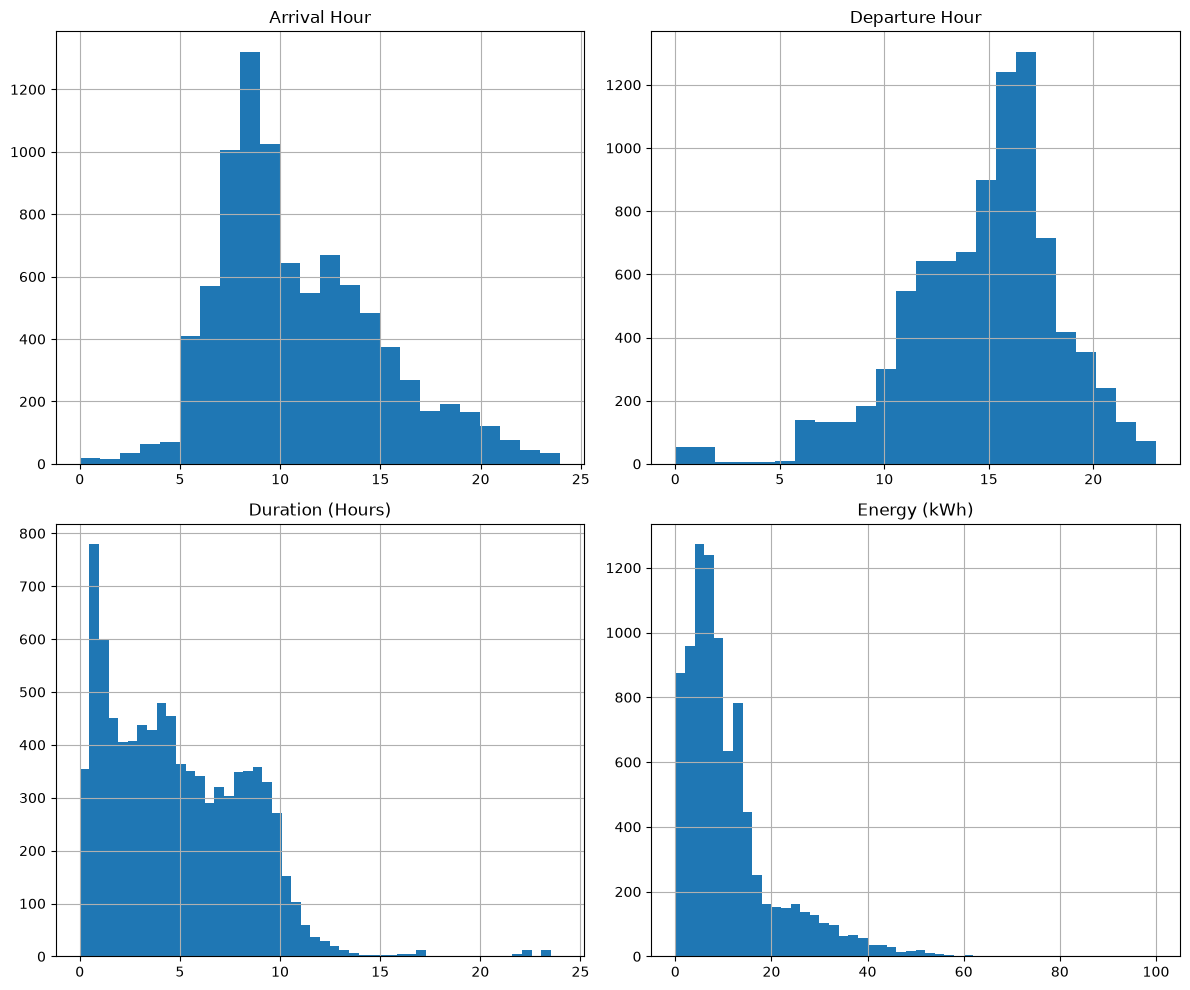

,duration_hours,energy_kwh,max_power_kw
count,8902.000000,8902.000000,8.902000e+03
mean,4.903790,11.098609,6.600000e+00
std,3.396893,9.830862,8.882283e-16
min,0.034444,0.227333,6.600000e+00
25%,1.967222,4.851250,6.600000e+00
50%,4.439306,8.171000,6.600000e+00
75%,7.534931,13.801750,6.600000e+00
max,23.310278,108.797242,6.600000e+00


In [28]:
if not cleaned_df.empty:
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    cleaned_df['arrival_hour'].hist(bins=24, ax=axes[0,0])
    axes[0,0].set_title('Arrival Hour')
    
    (cleaned_df['departure_time'].dt.hour).hist(bins=24, ax=axes[0,1])
    axes[0,1].set_title('Departure Hour')
    
    cleaned_df['duration_hours'].hist(bins=50, range=(0, 24), ax=axes[1,0])
    axes[1,0].set_title('Duration (Hours)')
    
    cleaned_df['energy_kwh'].hist(bins=50, range=(0, 100), ax=axes[1,1])
    axes[1,1].set_title('Energy (kWh)')
    
    plt.tight_layout()
    plt.show()
    
    display(cleaned_df[['duration_hours', 'energy_kwh', 'max_power_kw']].describe())
else:
    print("No data available for EDA.")

# 4. BEHAVIOUR TYPES

**ASSUMPTIONS:**
*   **Workplace**: Derived directly from the ACN dataset (which is workplace charging). We map the real API data rows straight through.
*   **Residential**: Assumes evening arrival (sampled between 17:00 and 20:00) and morning departure (sampled between 06:00 and 08:00). Energy is sampled from the ACN energy distribution to match realistic EV demands.
*   **Public**: Assumes midday/afternoon arrivals with short stays (1-3 hours).
*   **Fast Charging**: High power (50 kW), short duration (30-60 mins), energy is drawn appropriately.

In [29]:
def generate_synthetic_profiles(base_df, total_count, mix):
    profiles = []
    has_acn = not base_df.empty
    
    if has_acn:
        base_energy = base_df['energy_kwh'].values
    else:
        base_energy = np.random.normal(15, 5, total_count).clip(min=1)
        
    for ev_type, fraction in mix.items():
        count = int(total_count * fraction)
        if count == 0: continue
        
        type_energies = np.random.choice(base_energy, count)
        
        if ev_type == "workplace" and has_acn:
            # Use the EXACT ACN data sessions
            sampled_sessions = base_df.sample(n=count, replace=True).reset_index(drop=True)
            for i in range(count):
                row = sampled_sessions.iloc[i]
                # ACN returns sessionID or _id
                sid = row.get('sessionID', row.get('_id', f"acn_wp_{i}"))
                if pd.isna(sid):
                    sid = f"acn_wp_{i}"
                    
                profiles.append({
                    'session_id': sid,
                    'ev_type': ev_type,
                    'arrival_hour': row['arrival_hour'],
                    'departure_hour': row['arrival_hour'] + row['duration_hours'],
                    'energy_kwh': row['energy_kwh'],
                    'max_power_kw': row.get('max_power_kw', 6.6)
                })
        else:
            for i in range(count):
                session_id = f"{ev_type}_{i}"
                energy = type_energies[i]
                
                if ev_type == "workplace": # Fallback if no ACN data
                    arr_h = np.random.normal(8, 1.5) % 24
                    dur_h = np.random.normal(8, 2)
                    power = 6.6
                elif ev_type == "residential":
                    arr_h = np.random.uniform(17, 20)
                    dur_h = (np.random.uniform(6, 8) + 24) - arr_h
                    power = 6.6
                elif ev_type == "public":
                    arr_h = np.random.uniform(10, 15)
                    dur_h = np.random.uniform(1, 3)
                    power = 11.0
                elif ev_type == "fast_charging":
                    arr_h = np.random.uniform(8, 20)
                    dur_h = np.random.uniform(0.5, 1.0)
                    power = 50.0
                    
                dep_h = arr_h + dur_h

                max_energy_kwh = power * dur_h  # Charger cannot deliver more than P × time
                energy = min(energy, max_energy_kwh)  # Keep every synthetic session feasible

                profiles.append({
                    'session_id': session_id,
                    'ev_type': ev_type,
                    'arrival_hour': arr_h,
                    'departure_hour': dep_h,
                    'energy_kwh': energy,
                    'max_power_kw': power
                })
            
    return pd.DataFrame(profiles)

synthetic_df = generate_synthetic_profiles(cleaned_df, 1000, BEHAVIOUR_MIX)
display(synthetic_df['ev_type'].value_counts())

ev_type
workplace        500
residential      300
public           150
fast_charging     50
Name: count, dtype: int64

# 5. 15-MIN PROFILES

In [33]:
def convert_to_profiles(df, steps_per_day, time_res_min):
    records = []
    slot_hours = time_res_min / 60.0  # 15 min = 0.25 h

    for _, row in df.iterrows():
        arr_step = int((row["arrival_hour"] * 60) // time_res_min) % steps_per_day

        duration_hours = row["departure_hour"] - row["arrival_hour"]
        available_slots = max(1, int(np.floor(duration_hours / slot_hours)))

        dep_step = (arr_step + available_slots) % steps_per_day

        power_kw = row["max_power_kw"]
        requested_energy = row["energy_kwh"]

        max_slot_energy = power_kw * slot_hours
        max_possible_energy = available_slots * max_slot_energy

        target_energy = min(
            requested_energy,
            max_possible_energy,
        )  # Keep requested energy feasible on the 15-min grid

        profile = np.zeros(steps_per_day)
        remaining_energy = target_energy

        for offset in range(available_slots):
            if remaining_energy <= 1e-9:
                break

            step = (arr_step + offset) % steps_per_day

            slot_energy = min(
                remaining_energy,
                max_slot_energy,
            )

            profile[step] = slot_energy / slot_hours
            remaining_energy -= slot_energy

        record = {
            "session_id": row["session_id"],
            "ev_type": row["ev_type"],
            "arrival_step": arr_step,
            "departure_step": dep_step,
            "energy_kwh": target_energy,
            "max_power_kw": power_kw,
        }

        for i in range(steps_per_day):
            record[f"step_{i}"] = profile[i]

        records.append(record)

    return pd.DataFrame(records)


profiles_df = convert_to_profiles(
    synthetic_df,
    STEPS_PER_DAY,
    TIME_RESOLUTION_MINUTES,
)

print(f"Generated {len(profiles_df)} profiles.")

Generated 1000 profiles.


In [34]:
step_cols = [f"step_{i}" for i in range(STEPS_PER_DAY)]

profiles_df["simulated_energy_kwh"] = (
    profiles_df[step_cols].sum(axis=1)
    * (TIME_RESOLUTION_MINUTES / 60.0)
)

profiles_df["energy_diff"] = np.abs(
    profiles_df["energy_kwh"]
    - profiles_df["simulated_energy_kwh"]
)

print("Max energy difference:", profiles_df["energy_diff"].max())
print("Mean energy difference:", profiles_df["energy_diff"].mean())

Max energy difference: 1.4210854715202004e-14
Mean energy difference: 5.568878691519785e-16


# 6. VALIDATION

Max energy difference: 1.4210854715202004e-14


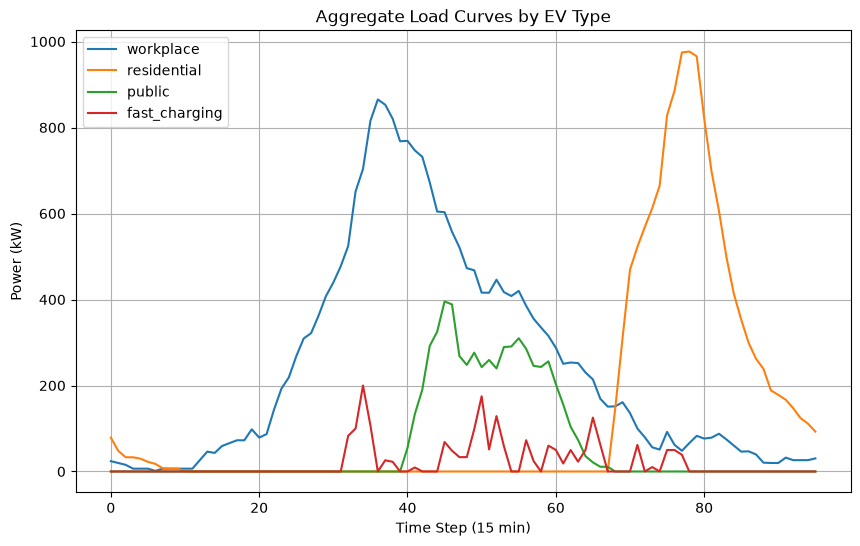

In [35]:
step_cols = [f'step_{i}' for i in range(STEPS_PER_DAY)]
profiles_df['simulated_energy_kwh'] = profiles_df[step_cols].sum(axis=1) * (TIME_RESOLUTION_MINUTES / 60.0)
profiles_df['energy_diff'] = np.abs(profiles_df['energy_kwh'] - profiles_df['simulated_energy_kwh'])

print("Max energy difference:", profiles_df['energy_diff'].max())

plt.figure(figsize=(10, 6))
for ev_type in BEHAVIOUR_MIX.keys():
    subset = profiles_df[profiles_df['ev_type'] == ev_type]
    if not subset.empty:
        agg_load = subset[step_cols].sum(axis=0)
        plt.plot(range(STEPS_PER_DAY), agg_load, label=ev_type)

plt.title('Aggregate Load Curves by EV Type')
plt.xlabel('Time Step (15 min)')
plt.ylabel('Power (kW)')
plt.legend()
plt.grid(True)
plt.show()

# 7. EXPORT

In [36]:
export_df = profiles_df.drop(columns=['simulated_energy_kwh', 'energy_diff'])
export_df.to_csv(OUTPUT_PATH, index=False)
print(f"Exported {len(export_df)} EV profiles to {OUTPUT_PATH}")

Exported 1000 EV profiles to data\ev_profiles.csv


# 8. CHANGELOG

**Audit & Fixes Applied:**
1. **Checklist Item 2 (Duration > 24h)**: Failed initially (was silently ignoring). Fixed by explicitly filtering out sessions longer than 24 hours in `clean_sessions`.
2. **Checklist Item 3 (Timezone)**: Failed initially (ACN API uses UTC/GMT, causing arrival peaks to shift). Fixed by converting `connectionTime` to `America/Los_Angeles`.
3. **Checklist Item 6 (Energy Consistency)**: Failed initially (silently truncated). Fixed by explicitly logging and clipping `energy_kwh` to `max_power_kw * duration_hours` in `clean_sessions`.
4. **Global Rules (Changelog)**: Added this changelog section to document the audit process.